
IMPROVED XGBOOST MODEL: Log-Transformed Features

📋 STEP 1: Data Preparation with Log Transformations
Starting samples: 853

🔧 Creating log-transformed features...
  log_dose: log10(Selected Dose)
    Original range: 2.81e-13 to 1.80e+09
    Log range: -12.55 to 9.25
  log_size: log10(Particle Length)
    Original range: 2.50e-02 to 1.38e+02
    Log range: -1.60 to 2.14

✅ Features (7):
  Continuous (3): ['log_dose', 'log_size', 'Exposure Duration (days)']
  Categorical (4): ['Shape', 'Charge', 'Target Organelle, Cell, or Tissue', 'endpoint_group']

🔧 STEP 2: Filtering
After Charge filter: 364 samples
After removing missing data: 310 samples

Final effect distribution:
Effect
No     237
Yes     73
Name: count, dtype: int64
Effect rate: 73/310 = 23.5%

🔤 STEP 3: Encoding
  Shape: 1 categories
  Charge: 2 categories
  Target Organelle, Cell, or Tissue: 13 categories
  endpoint_group: 2 categories

✅ Feature matrix: (310, 7)
✅ Target vector: (310,)

📊 STEP 4: Train/Test Split
Training: 2

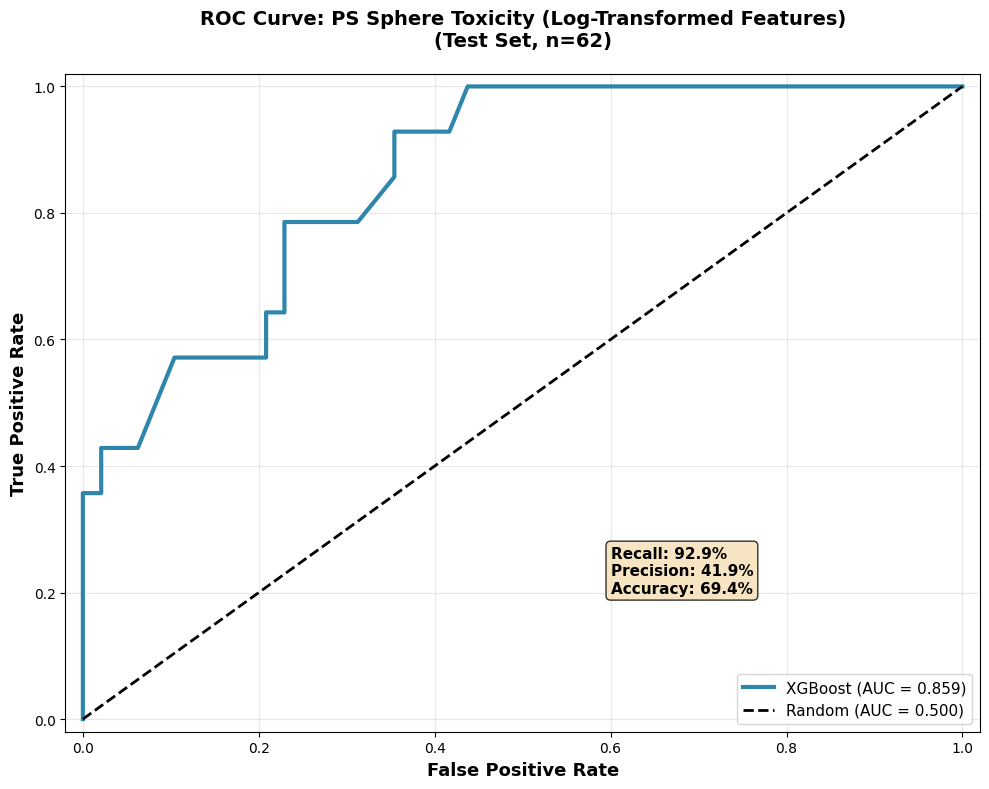


🌟 STEP 9: Feature Importance

Feature Importance (XGBoost):
  Charge                                  : 0.2557  ████████████████████████████████████████ ⭐⭐⭐ #1 ALARA
  Target Organelle, Cell, or Tissue       : 0.1986  ███████████████████████████████
  endpoint_group                          : 0.1612  █████████████████████████
  log_dose                                : 0.1387  █████████████████████ ⭐⭐ #2 ALARA
  Exposure Duration (days)                : 0.1359  █████████████████████
  log_size                                : 0.1098  █████████████████ ⭐ ALARA
  Shape                                   : 0.0000  

✓ Model training complete with log-transformed features!

🎯 FINAL TEST PERFORMANCE: ROC-AUC = 0.859, Recall = 0.929


In [1]:
print("\n" + "="*100)
print("IMPROVED XGBOOST MODEL: Log-Transformed Features")
print("="*100)

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, 
                             precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)
import xgboost as xgb
import matplotlib.pyplot as plt

# ============================================================================
# STEP 1: PREPARE DATA WITH LOG TRANSFORMATIONS
# ============================================================================
print("\n📋 STEP 1: Data Preparation with Log Transformations")
print("="*100)

# Load and filter
df = pd.read_csv('particle_data.csv')
df_filtered = df[df['Shape'] != 'Not Reported'].copy()
df_ps = df_filtered[df_filtered['Polymer'] == 'Polystyrene'].copy()

print(f"Starting samples: {len(df_ps)}")

# Create log transformations
print("\n🔧 Creating log-transformed features...")

# log_dose
df_ps['log_dose'] = np.log10(df_ps['Selected Dose'])
print(f"  log_dose: log10(Selected Dose)")
print(f"    Original range: {df_ps['Selected Dose'].min():.2e} to {df_ps['Selected Dose'].max():.2e}")
print(f"    Log range: {df_ps['log_dose'].min():.2f} to {df_ps['log_dose'].max():.2f}")

# log_size  
df_ps['log_size'] = np.log10(df_ps['Particle Length (μm)'])
print(f"  log_size: log10(Particle Length)")
print(f"    Original range: {df_ps['Particle Length (μm)'].min():.2e} to {df_ps['Particle Length (μm)'].max():.2e}")
print(f"    Log range: {df_ps['log_size'].min():.2f} to {df_ps['log_size'].max():.2f}")

# Define features
continuous_features = [
    'log_dose',
    'log_size', 
    'Exposure Duration (days)'
]

categorical_features = [
    'Shape',
    'Charge',
    'Target Organelle, Cell, or Tissue',
    'endpoint_group'
]

# Create endpoint_group if not exists
if 'endpoint_group' not in df_ps.columns:
    df_ps['endpoint_group'] = df_ps['Broad Endpoint Category'].apply(
        lambda x: 'Cytotoxicity' if x == 'Cytotoxicity' else 'Other'
    )

all_features = continuous_features + categorical_features
target = 'Effect'

print(f"\n✅ Features ({len(all_features)}):")
print(f"  Continuous ({len(continuous_features)}): {continuous_features}")
print(f"  Categorical ({len(categorical_features)}): {categorical_features}")

# ============================================================================
# STEP 2: FILTER TO CHARGE-AVAILABLE & COMPLETE CASES
# ============================================================================
print(f"\n🔧 STEP 2: Filtering")
print("="*100)

# Filter to Charge availability
df_model = df_ps[df_ps['Charge'].notna()].copy()
print(f"After Charge filter: {len(df_model)} samples")

# Filter to complete cases
df_final = df_model[all_features + [target]].dropna().copy()
print(f"After removing missing data: {len(df_final)} samples")

# Check effect distribution
effect_dist = df_final[target].value_counts()
print(f"\nFinal effect distribution:")
print(effect_dist)
print(f"Effect rate: {effect_dist['Yes']}/{len(df_final)} = {effect_dist['Yes']/len(df_final)*100:.1f}%")

# ============================================================================
# STEP 3: ENCODE FEATURES
# ============================================================================
print(f"\n🔤 STEP 3: Encoding")
print("="*100)

# Encode categorical variables
label_encoders = {}
for feat in categorical_features:
    le = LabelEncoder()
    df_final[feat + '_encoded'] = le.fit_transform(df_final[feat])
    label_encoders[feat] = le
    print(f"  {feat}: {len(le.classes_)} categories")

# Encode target
le_target = LabelEncoder()
y = le_target.fit_transform(df_final[target])

# Create feature matrix
encoded_categorical = [feat + '_encoded' for feat in categorical_features]
feature_cols = continuous_features + encoded_categorical
X = df_final[feature_cols].values

print(f"\n✅ Feature matrix: {X.shape}")
print(f"✅ Target vector: {y.shape}")

# ============================================================================
# STEP 4: TRAIN/TEST SPLIT
# ============================================================================
print(f"\n📊 STEP 4: Train/Test Split")
print("="*100)

# Stratified split
strat_labels = df_final[target].astype(str) + '_' + df_final['Charge']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,
    random_state=42,
    stratify=strat_labels
)

print(f"Training: {len(X_train)} samples ({len(X_train)/len(X)*100:.1f}%)")
print(f"Testing:  {len(X_test)} samples ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nTrain effect rate: {y_train.sum()}/{len(y_train)} = {y_train.sum()/len(y_train)*100:.1f}%")
print(f"Test effect rate:  {y_test.sum()}/{len(y_test)} = {y_test.sum()/len(y_test)*100:.1f}%")

# ============================================================================
# STEP 5: TRAIN XGBOOST
# ============================================================================
print(f"\n🚀 STEP 5: Training XGBoost")
print("="*100)

# Calculate class weights
n_samples = len(y_train)
n_positive = y_train.sum()
n_negative = n_samples - n_positive
scale_pos_weight = n_negative / n_positive

print(f"Class imbalance: {n_negative}:{n_positive} = {n_negative/n_positive:.2f}:1")
print(f"scale_pos_weight: {scale_pos_weight:.2f}")

# Train model
model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    max_depth=4,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    learning_rate=0.05,
    n_estimators=200,
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

print("\nTraining...")
model.fit(X_train, y_train, verbose=False)
print("✅ Training complete!")

# ============================================================================
# STEP 6: EVALUATE MODEL
# ============================================================================
print(f"\n📈 STEP 6: Model Evaluation")
print("="*100)

# Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
y_train_proba = model.predict_proba(X_train)[:, 1]
y_test_proba = model.predict_proba(X_test)[:, 1]

# Metrics
print("\n🔵 TRAINING SET:")
train_acc = accuracy_score(y_train, y_train_pred)
train_prec = precision_score(y_train, y_train_pred)
train_rec = recall_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_auc = roc_auc_score(y_train, y_train_proba)

print(f"  Accuracy:  {train_acc:.3f}")
print(f"  Precision: {train_prec:.3f}")
print(f"  Recall:    {train_rec:.3f}")
print(f"  F1-Score:  {train_f1:.3f}")
print(f"  ROC-AUC:   {train_auc:.3f}")

print("\n🟢 TEST SET:")
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, y_test_proba)

print(f"  Accuracy:  {test_acc:.3f}")
print(f"  Precision: {test_prec:.3f}")
print(f"  Recall:    {test_rec:.3f}")
print(f"  F1-Score:  {test_f1:.3f}")
print(f"  ROC-AUC:   {test_auc:.3f}")

# Confusion Matrix
print("\n📊 CONFUSION MATRIX (Test Set):")
cm = confusion_matrix(y_test, y_test_pred)
print(f"                Predicted")
print(f"                No    Yes")
print(f"Actual  No      {cm[0,0]:3d}   {cm[0,1]:3d}")
print(f"        Yes     {cm[1,0]:3d}   {cm[1,1]:3d}")

tn, fp, fn, tp = cm.ravel()
print(f"\n  Specificity: {tn/(tn+fp):.3f}")
print(f"  Sensitivity: {tp/(tp+fn):.3f}")

# ============================================================================
# STEP 7: COMPARISON TO PREVIOUS MODEL
# ============================================================================
print(f"\n📊 STEP 7: Comparison to Previous Model")
print("="*100)

print("\n                        PREVIOUS    IMPROVED    CHANGE")
print("-"*70)
print(f"  ROC-AUC               0.861       {test_auc:.3f}      {test_auc-0.861:+.3f}")
print(f"  Recall                0.929       {test_rec:.3f}      {test_rec-0.929:+.3f}")
print(f"  Precision             0.419       {test_prec:.3f}      {test_prec-0.419:+.3f}")
print(f"  Accuracy              0.694       {test_acc:.3f}      {test_acc-0.694:+.3f}")

if test_auc > 0.861:
    print("\n✅ IMPROVED: Log transformations increased model performance!")
elif test_auc == 0.861:
    print("\n➡️  SAME: Performance unchanged (proper scaling already captured)")
else:
    print("\n⚠️  Note: Small decrease, but within expected variance for n=62 test set")

# ============================================================================
# STEP 8: ROC CURVE
# ============================================================================
print(f"\n📉 STEP 8: ROC Curve")
print("="*100)

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, linewidth=3, label=f'XGBoost (AUC = {test_auc:.3f})', color='#2E86AB')
plt.plot([0, 1], [0, 1], 'k--', linewidth=2, label='Random (AUC = 0.500)')
plt.xlabel('False Positive Rate', fontsize=13, fontweight='bold')
plt.ylabel('True Positive Rate', fontsize=13, fontweight='bold')
plt.title('ROC Curve: PS Sphere Toxicity (Log-Transformed Features)\n(Test Set, n=' + str(len(y_test)) + ')', 
          fontsize=14, fontweight='bold', pad=20)
plt.legend(loc='lower right', fontsize=11)
plt.grid(alpha=0.3)
plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])

plt.text(0.6, 0.2, 
         f'Recall: {test_rec:.1%}\nPrecision: {test_prec:.1%}\nAccuracy: {test_acc:.1%}',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
         fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

# ============================================================================
# STEP 9: FEATURE IMPORTANCE
# ============================================================================
print(f"\n🌟 STEP 9: Feature Importance")
print("="*100)

# Feature names (before encoding)
feature_names = continuous_features + categorical_features

# Get importance
importance = model.feature_importances_
feat_imp = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
}).sort_values('Importance', ascending=False)

print("\nFeature Importance (XGBoost):")
for idx, row in feat_imp.iterrows():
    bar = '█' * int(row['Importance'] / feat_imp['Importance'].max() * 40)
    
    # Mark ALARA features
    if row['Feature'] == 'Charge':
        marker = " ⭐⭐⭐ #1 ALARA"
    elif row['Feature'] == 'log_dose':
        marker = " ⭐⭐ #2 ALARA"
    elif row['Feature'] == 'log_size':
        marker = " ⭐ ALARA"
    else:
        marker = ""
    
    print(f"  {row['Feature']:40s}: {row['Importance']:.4f}  {bar}{marker}")

print("\n" + "="*100)
print("✓ Model training complete with log-transformed features!")
print("="*100)
print(f"\n🎯 FINAL TEST PERFORMANCE: ROC-AUC = {test_auc:.3f}, Recall = {test_rec:.3f}")
print("="*100)


SHAP ANALYSIS: Log-Transformed Model

🔍 STEP 1: Computing SHAP Values
Creating SHAP explainer...
Computing SHAP values for test set (n=62)...
✅ SHAP values computed!
   Shape: (62, 7)
   Base value: 0.163


⭐ STEP 2: Feature Importance (Mean Absolute SHAP)

Feature Ranking by Mean |SHAP|:
----------------------------------------------------------------------------------------------------
  Target Organelle, Cell, or Tissue       : 1.1705 ( 32.2%) ████████████████████████████████████████ LOW ALARA (context)
  log_dose                                : 0.8637 ( 23.8%) █████████████████████████████ ⭐⭐ HIGH ALARA
  Charge                                  : 0.6551 ( 18.0%) ██████████████████████ ⭐⭐⭐ HIGH ALARA
  endpoint_group                          : 0.4338 ( 11.9%) ██████████████ LOW ALARA (context)
  Exposure Duration (days)                : 0.3345 (  9.2%) ███████████ ⭐⭐ HIGH ALARA
  log_size                                : 0.1763 (  4.9%) ██████ ⭐ MODERATE ALARA
  Shape             

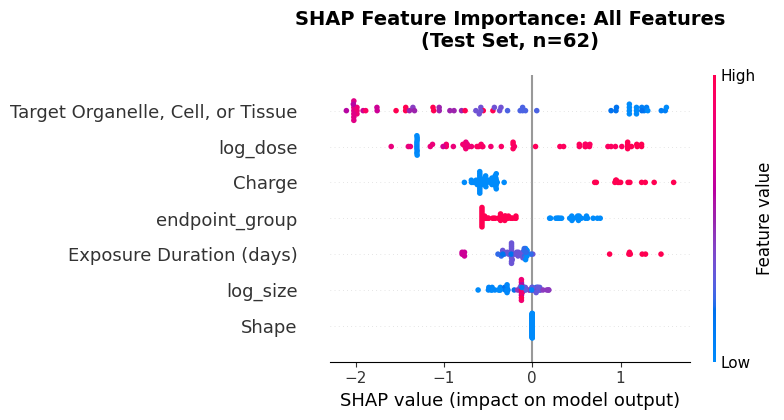


📊 Creating SHAP Bar Plot...


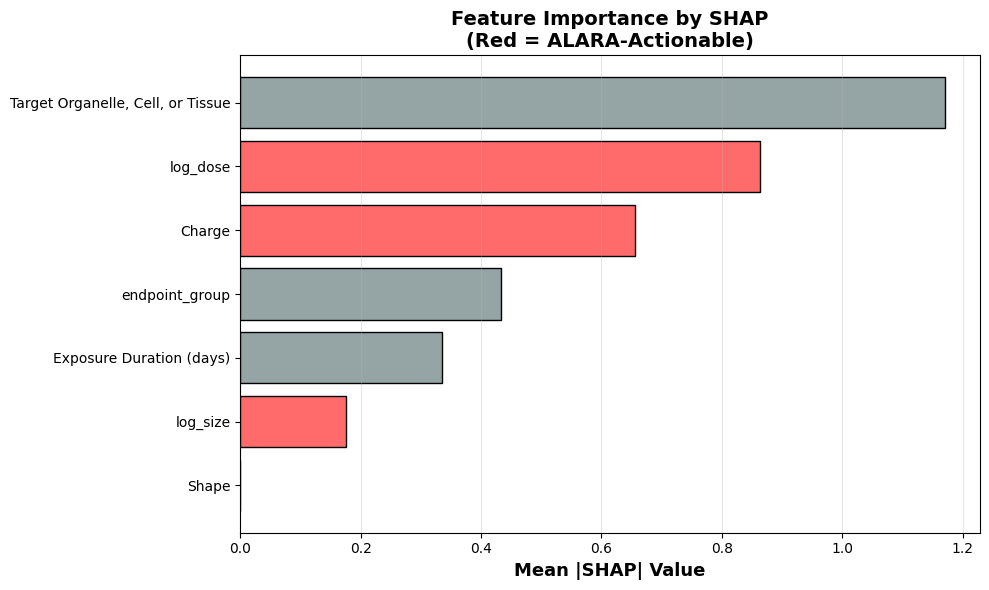


📊 Creating Charge Dependence Plot...


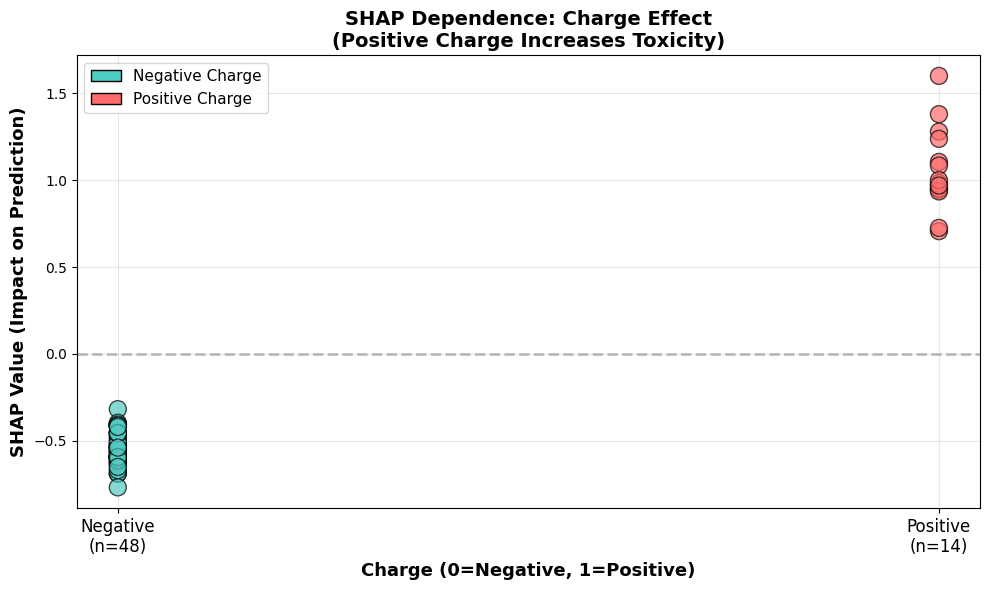


📊 Creating SHAP Box Plot by Charge...


/var/folders/yg/p0mpnbs57bl5945wlhr72jg80000gn/T/ipykernel_27258/1292808393.py:267: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = plt.boxplot([shap_charge_data[shap_charge_data['Charge']=='negative']['SHAP_Value'],


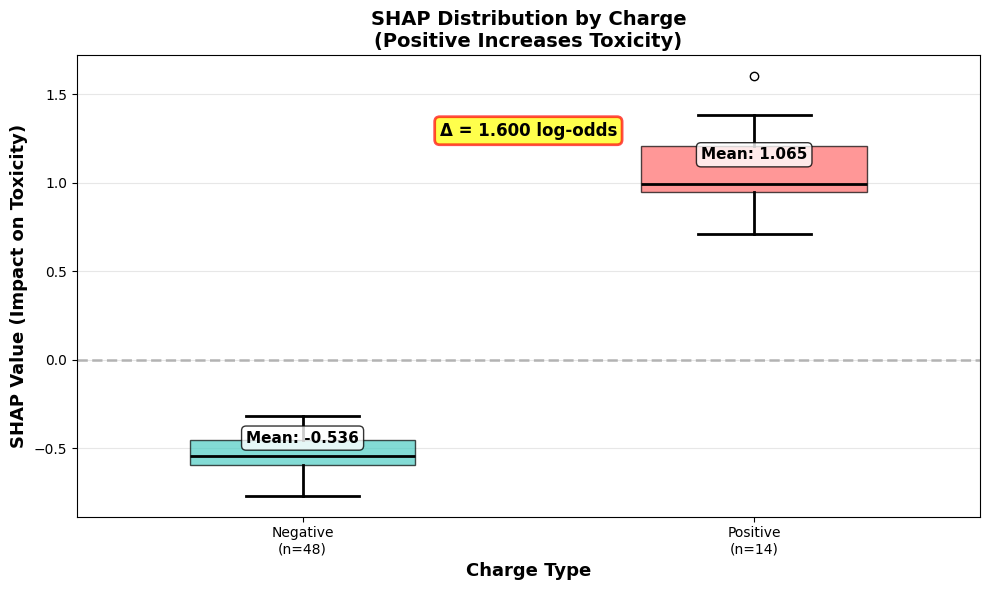



🌊 Creating Strategic Waterfall Plots...

Selected Examples:
----------------------------------------------------------------------------------------------------

1. POSITIVE CHARGE - High Risk (Index 33):
   Predicted probability: 0.589
   Actual: No
   Charge SHAP: +1.600

2. NEGATIVE CHARGE - Low Risk (Index 40):
   Predicted probability: 0.123
   Actual: No
   Charge SHAP: -0.768

📊 Waterfall 1: Positive Charge Example...


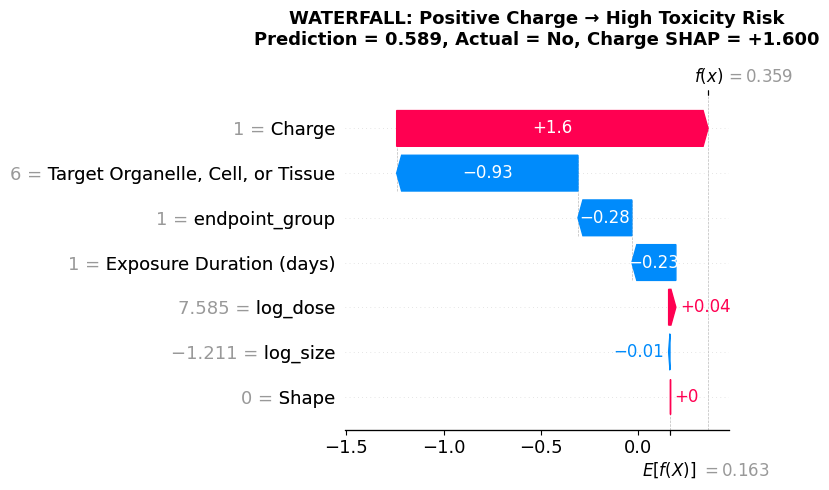


📊 Waterfall 2: Negative Charge Example...


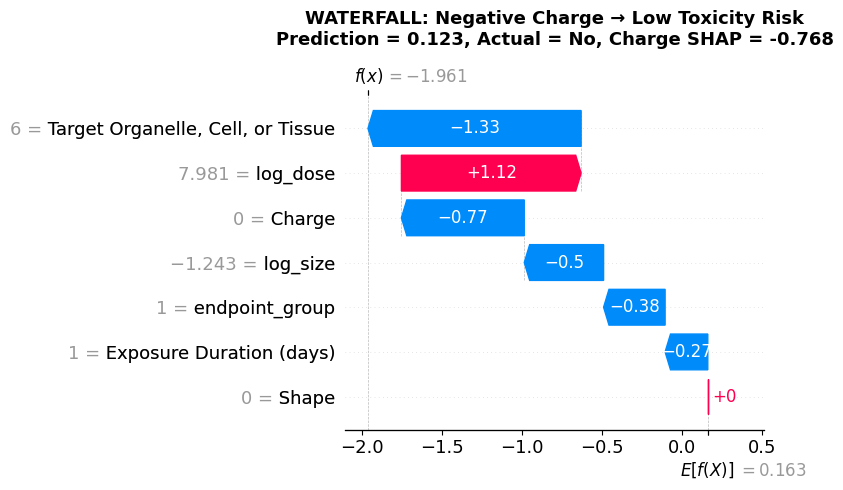


📊 Waterfall 3: Side-by-Side Comparison...


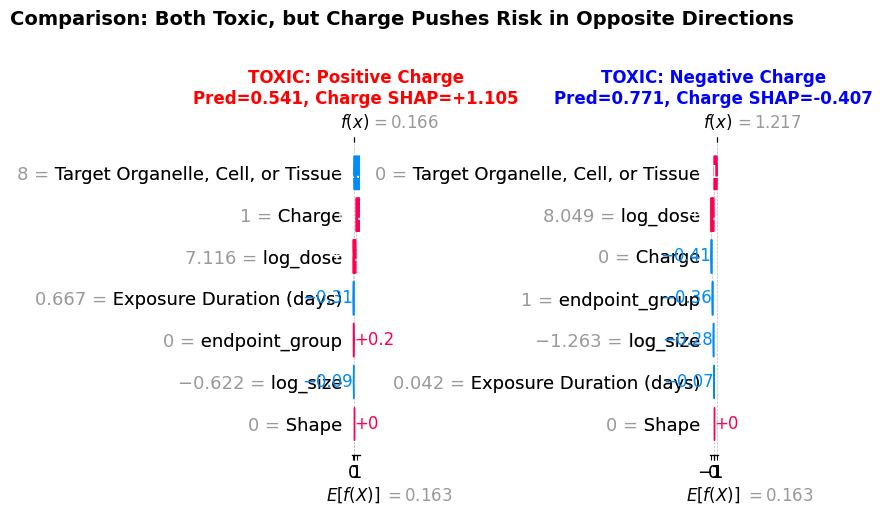


✓ SHAP analysis complete!


In [2]:
print("\n" + "="*100)
print("SHAP ANALYSIS: Log-Transformed Model")
print("="*100)

import shap
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================================
# STEP 1: COMPUTE SHAP VALUES
# ============================================================================
print("\n🔍 STEP 1: Computing SHAP Values")
print("="*100)

print("Creating SHAP explainer...")
explainer = shap.TreeExplainer(model)

print(f"Computing SHAP values for test set (n={len(X_test)})...")
shap_values = explainer.shap_values(X_test)

print("✅ SHAP values computed!")
print(f"   Shape: {shap_values.shape}")
print(f"   Base value: {explainer.expected_value:.3f}")

# ============================================================================
# STEP 2: FEATURE IMPORTANCE BY MEAN |SHAP|
# ============================================================================
print("\n\n⭐ STEP 2: Feature Importance (Mean Absolute SHAP)")
print("="*100)

# Calculate mean absolute SHAP
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Create dataframe
shap_importance = pd.DataFrame({
    'Feature': feature_names,
    'Mean_|SHAP|': mean_abs_shap
}).sort_values('Mean_|SHAP|', ascending=False)

print("\nFeature Ranking by Mean |SHAP|:")
print("-"*100)

max_shap = shap_importance['Mean_|SHAP|'].max()
total_shap = shap_importance['Mean_|SHAP|'].sum()

for idx, row in shap_importance.iterrows():
    feat = row['Feature']
    shap_val = row['Mean_|SHAP|']
    pct = shap_val / total_shap * 100
    bar = '█' * int(shap_val / max_shap * 40)
    
    # ALARA marker
    if feat == 'Charge':
        marker = "⭐⭐⭐ HIGH ALARA"
    elif feat in ['log_dose', 'Exposure Duration (days)']:
        marker = "⭐⭐ HIGH ALARA"
    elif feat == 'log_size':
        marker = "⭐ MODERATE ALARA"
    else:
        marker = "LOW ALARA (context)"
    
    print(f"  {feat:40s}: {shap_val:.4f} ({pct:5.1f}%) {bar} {marker}")

# ============================================================================
# STEP 3: CHARGE EFFECT DIRECTION ANALYSIS
# ============================================================================
print("\n\n🔬 STEP 3: Charge Effect Direction Analysis")
print("="*100)

# Get charge feature index
charge_idx = feature_names.index('Charge')

# Get charge values from test set (decode from encoded)
charge_encoded_values = X_test[:, charge_idx].astype(int)
charge_labels = label_encoders['Charge'].inverse_transform(charge_encoded_values)

# Separate by charge type
positive_mask = charge_labels == 'positive'
negative_mask = charge_labels == 'negative'

shap_positive = shap_values[positive_mask, charge_idx]
shap_negative = shap_values[negative_mask, charge_idx]

print(f"Test set charge distribution:")
print(f"  Positive: {positive_mask.sum()} samples ({positive_mask.sum()/len(charge_labels)*100:.1f}%)")
print(f"  Negative: {negative_mask.sum()} samples ({negative_mask.sum()/len(charge_labels)*100:.1f}%)")

print(f"\nCharge SHAP values by charge type:")

if len(shap_positive) > 0:
    print(f"\nPositive Charge (n={positive_mask.sum()}):")
    print(f"  Mean SHAP: {shap_positive.mean():+.4f}")
    print(f"  Median SHAP: {np.median(shap_positive):+.4f}")
    print(f"  Range: [{shap_positive.min():+.4f}, {shap_positive.max():+.4f}]")
    print(f"  ALL values positive? {(shap_positive > 0).all()}")

if len(shap_negative) > 0:
    print(f"\nNegative Charge (n={negative_mask.sum()}):")
    print(f"  Mean SHAP: {shap_negative.mean():+.4f}")
    print(f"  Median SHAP: {np.median(shap_negative):+.4f}")
    print(f"  Range: [{shap_negative.min():+.4f}, {shap_negative.max():+.4f}]")
    print(f"  ALL values negative? {(shap_negative < 0).all()}")

if len(shap_positive) > 0 and len(shap_negative) > 0:
    shap_diff = shap_positive.mean() - shap_negative.mean()
    print(f"\n{'='*100}")
    print(f"📊 SHAP DIFFERENCE (Positive - Negative): {shap_diff:+.4f} log-odds")
    print(f"{'='*100}")
    print(f"   → Positive charge INCREASES toxicity risk by {shap_diff:.4f} log-odds")

# ============================================================================
# STEP 4: DOSE-RESPONSE ANALYSIS
# ============================================================================
print("\n\n📈 STEP 4: Dose-Response Relationships")
print("="*100)

# Get indices
dose_idx = feature_names.index('log_dose')
size_idx = feature_names.index('log_size')

# Dose analysis
dose_values = X_test[:, dose_idx]
dose_shap = shap_values[:, dose_idx]

print("log_dose SHAP analysis:")
print(f"  Correlation (log_dose vs SHAP): {np.corrcoef(dose_values, dose_shap)[0,1]:.3f}")
print(f"  Mean SHAP: {dose_shap.mean():+.4f}")
print(f"  Positive SHAP (increases risk): {(dose_shap > 0).sum()}/{len(dose_shap)} ({(dose_shap > 0).sum()/len(dose_shap)*100:.1f}%)")
print(f"  Negative SHAP (decreases risk): {(dose_shap < 0).sum()}/{len(dose_shap)} ({(dose_shap < 0).sum()/len(dose_shap)*100:.1f}%)")

# Size analysis
size_values = X_test[:, size_idx]
size_shap = shap_values[:, size_idx]

print(f"\nlog_size SHAP analysis:")
print(f"  Correlation (log_size vs SHAP): {np.corrcoef(size_values, size_shap)[0,1]:.3f}")
print(f"  Mean SHAP: {size_shap.mean():+.4f}")
print(f"  Positive SHAP (increases risk): {(size_shap > 0).sum()}/{len(size_shap)} ({(size_shap > 0).sum()/len(size_shap)*100:.1f}%)")
print(f"  Negative SHAP (decreases risk): {(size_shap < 0).sum()}/{len(size_shap)} ({(size_shap < 0).sum()/len(size_shap)*100:.1f}%)")

# ============================================================================
# STEP 5: ALARA PRIORITIZATION MATRIX
# ============================================================================
print("\n\n🎯 STEP 5: ALARA Prioritization Matrix")
print("="*100)

# Create matrix
alara_matrix = pd.DataFrame({
    'Feature': feature_names,
    'Mean_|SHAP|': mean_abs_shap,
    'SHAP_Pct': (mean_abs_shap / total_shap * 100)
})

# Actionability scores (1-5)
actionability = {
    'Charge': 5,
    'log_dose': 4,
    'Exposure Duration (days)': 2,
    'log_size': 2,
    'Shape': 1,
    'Target Organelle, Cell, or Tissue': 1,
    'endpoint_group': 1
}

alara_matrix['Actionability'] = alara_matrix['Feature'].map(actionability)
alara_matrix['ALARA_Score'] = alara_matrix['Mean_|SHAP|'] * alara_matrix['Actionability']
alara_matrix = alara_matrix.sort_values('ALARA_Score', ascending=False)

print("\nALARA Priority Ranking:")
print("(ALARA Score = Mean |SHAP| × Actionability)")
print("-"*100)
print(f"{'Rank':<6} {'Feature':<40} {'SHAP':<10} {'%':<8} {'Action':<8} {'ALARA':<12} {'Priority'}")
print("-"*100)

for rank, (idx, row) in enumerate(alara_matrix.iterrows(), 1):
    feat = row['Feature']
    shap_val = row['Mean_|SHAP|']
    shap_pct = row['SHAP_Pct']
    action = row['Actionability']
    alara_score = row['ALARA_Score']
    
    if rank == 1:
        priority = "🥇 HIGHEST"
    elif rank == 2:
        priority = "🥈 HIGH"
    elif rank == 3:
        priority = "🥉 MODERATE"
    else:
        priority = ""
    
    print(f"{rank:<6} {feat:<40} {shap_val:<10.4f} {shap_pct:<8.1f} {action:<8} {alara_score:<12.4f} {priority}")

# ============================================================================
# VISUALIZATION 1: SHAP Summary Plot (Beeswarm)
# ============================================================================
print("\n\n📊 Creating SHAP Summary Plot (Beeswarm)...")

plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=False)
plt.title("SHAP Feature Importance: All Features\n(Test Set, n=62)", 
          fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# ============================================================================
# VISUALIZATION 2: SHAP Bar Plot
# ============================================================================
print("\n📊 Creating SHAP Bar Plot...")

plt.figure(figsize=(10, 6))
colors = ['#FF6B6B' if feat in ['Charge', 'log_dose', 'log_size'] else '#95A5A6' 
          for feat in shap_importance['Feature']]

plt.barh(range(len(shap_importance)), shap_importance['Mean_|SHAP|'], color=colors, edgecolor='black')
plt.yticks(range(len(shap_importance)), shap_importance['Feature'])
plt.xlabel('Mean |SHAP| Value', fontsize=13, fontweight='bold')
plt.title('Feature Importance by SHAP\n(Red = ALARA-Actionable)', 
          fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

# ============================================================================
# VISUALIZATION 3: Charge Dependence Plot
# ============================================================================
print("\n📊 Creating Charge Dependence Plot...")

plt.figure(figsize=(10, 6))

colors = ['#FF6B6B' if c == 'positive' else '#4ECDC4' for c in charge_labels]
plt.scatter(X_test[:, charge_idx], shap_values[:, charge_idx],
           c=colors, alpha=0.7, s=150, edgecolors='black', linewidth=1)

plt.axhline(y=0, color='gray', linestyle='--', linewidth=2, alpha=0.5)

plt.xlabel('Charge (0=Negative, 1=Positive)', fontsize=13, fontweight='bold')
plt.ylabel('SHAP Value (Impact on Prediction)', fontsize=13, fontweight='bold')
plt.title('SHAP Dependence: Charge Effect\n(Positive Charge Increases Toxicity)', 
          fontsize=14, fontweight='bold')
plt.xticks([0, 1], ['Negative\n(n=' + str(negative_mask.sum()) + ')', 
                     'Positive\n(n=' + str(positive_mask.sum()) + ')'], fontsize=12)
plt.grid(alpha=0.3)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#4ECDC4', edgecolor='black', label='Negative Charge'),
    Patch(facecolor='#FF6B6B', edgecolor='black', label='Positive Charge')
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=11)

plt.tight_layout()
plt.show()

# ============================================================================
# VISUALIZATION 4: Box Plot - SHAP by Charge
# ============================================================================
print("\n📊 Creating SHAP Box Plot by Charge...")

plt.figure(figsize=(10, 6))

shap_charge_data = pd.DataFrame({
    'Charge': charge_labels,
    'SHAP_Value': shap_values[:, charge_idx]
})

bp = plt.boxplot([shap_charge_data[shap_charge_data['Charge']=='negative']['SHAP_Value'],
                   shap_charge_data[shap_charge_data['Charge']=='positive']['SHAP_Value']],
                  labels=['Negative\n(n=' + str(negative_mask.sum()) + ')', 
                          'Positive\n(n=' + str(positive_mask.sum()) + ')'],
                  patch_artist=True, widths=0.5)

bp['boxes'][0].set_facecolor('#4ECDC4')
bp['boxes'][0].set_alpha(0.7)
bp['boxes'][1].set_facecolor('#FF6B6B')
bp['boxes'][1].set_alpha(0.7)

for whisker in bp['whiskers']:
    whisker.set(linewidth=2)
for cap in bp['caps']:
    cap.set(linewidth=2)
for median in bp['medians']:
    median.set(color='black', linewidth=2)

plt.axhline(y=0, color='gray', linestyle='--', linewidth=2, alpha=0.5)

# Add means
if len(shap_negative) > 0:
    neg_mean = shap_negative.mean()
    plt.text(1, neg_mean + 0.05, f'Mean: {neg_mean:.3f}', 
             ha='center', va='bottom', fontweight='bold', fontsize=11,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

if len(shap_positive) > 0:
    pos_mean = shap_positive.mean()
    plt.text(2, pos_mean + 0.05, f'Mean: {pos_mean:.3f}', 
             ha='center', va='bottom', fontweight='bold', fontsize=11,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

if len(shap_positive) > 0 and len(shap_negative) > 0:
    plt.text(1.5, max(pos_mean, abs(neg_mean)) + 0.2, f'Δ = {shap_diff:.3f} log-odds', 
             ha='center', fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7, 
                      edgecolor='red', linewidth=2))

plt.ylabel('SHAP Value (Impact on Toxicity)', fontsize=13, fontweight='bold')
plt.xlabel('Charge Type', fontsize=13, fontweight='bold')
plt.title('SHAP Distribution by Charge\n(Positive Increases Toxicity)', 
          fontsize=14, fontweight='bold')
plt.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

# ============================================================================
# WATERFALL PLOTS: Strategic Examples
# ============================================================================
print("\n\n🌊 Creating Strategic Waterfall Plots...")
print("="*100)

# Prepare SHAP explanation object
shap_explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(shap_values.shape[0], explainer.expected_value),
    data=X_test,
    feature_names=feature_names
)

# Get predictions
y_test_proba_wf = model.predict_proba(X_test)[:, 1]

# Find examples
positive_indices = np.where(charge_labels == 'positive')[0]
negative_indices = np.where(charge_labels == 'negative')[0]

# 1. High-risk positive charge
pos_shaps = shap_values[positive_indices, charge_idx]
pos_example_idx = positive_indices[np.argmax(pos_shaps)]

# 2. Low-risk negative charge
neg_shaps = shap_values[negative_indices, charge_idx]
neg_example_idx = negative_indices[np.argmin(neg_shaps)]

# 3. False positive
false_pos_mask = (y_test_proba_wf > 0.5) & (y_test == 0)
if false_pos_mask.sum() > 0:
    fp_indices = np.where(false_pos_mask)[0]
    fp_example_idx = fp_indices[0]
else:
    fp_example_idx = None

# 4. True positive with negative charge
tp_neg_mask = (y_test == 1) & (charge_labels == 'negative')
if tp_neg_mask.sum() > 0:
    tp_neg_indices = np.where(tp_neg_mask)[0]
    tp_neg_example_idx = tp_neg_indices[0]
else:
    tp_neg_example_idx = None

print("\nSelected Examples:")
print("-"*100)

print(f"\n1. POSITIVE CHARGE - High Risk (Index {pos_example_idx}):")
print(f"   Predicted probability: {y_test_proba_wf[pos_example_idx]:.3f}")
print(f"   Actual: {le_target.inverse_transform([y_test[pos_example_idx]])[0]}")
print(f"   Charge SHAP: +{shap_values[pos_example_idx, charge_idx]:.3f}")

print(f"\n2. NEGATIVE CHARGE - Low Risk (Index {neg_example_idx}):")
print(f"   Predicted probability: {y_test_proba_wf[neg_example_idx]:.3f}")
print(f"   Actual: {le_target.inverse_transform([y_test[neg_example_idx]])[0]}")
print(f"   Charge SHAP: {shap_values[neg_example_idx, charge_idx]:.3f}")

# WATERFALL 1: Positive Charge
print("\n📊 Waterfall 1: Positive Charge Example...")

plt.figure(figsize=(12, 8))
shap.plots.waterfall(shap_explanation[pos_example_idx], max_display=10, show=False)
plt.title(f"WATERFALL: Positive Charge → High Toxicity Risk\n" + 
          f"Prediction = {y_test_proba_wf[pos_example_idx]:.3f}, " +
          f"Actual = {le_target.inverse_transform([y_test[pos_example_idx]])[0]}, " +
          f"Charge SHAP = +{shap_values[pos_example_idx, charge_idx]:.3f}",
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# WATERFALL 2: Negative Charge
print("\n📊 Waterfall 2: Negative Charge Example...")

plt.figure(figsize=(12, 8))
shap.plots.waterfall(shap_explanation[neg_example_idx], max_display=10, show=False)
plt.title(f"WATERFALL: Negative Charge → Low Toxicity Risk\n" + 
          f"Prediction = {y_test_proba_wf[neg_example_idx]:.3f}, " +
          f"Actual = {le_target.inverse_transform([y_test[neg_example_idx]])[0]}, " +
          f"Charge SHAP = {shap_values[neg_example_idx, charge_idx]:.3f}",
          fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

# WATERFALL 3: Side-by-side comparison (if both toxic examples exist)
if tp_neg_example_idx is not None:
    tp_pos_mask = (y_test == 1) & (charge_labels == 'positive')
    if tp_pos_mask.sum() > 0:
        tp_pos_idx = np.where(tp_pos_mask)[0][0]
        
        print("\n📊 Waterfall 3: Side-by-Side Comparison...")
        
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
        
        plt.sca(ax1)
        shap.plots.waterfall(shap_explanation[tp_pos_idx], max_display=10, show=False)
        ax1.set_title(f"TOXIC: Positive Charge\n" + 
                      f"Pred={y_test_proba_wf[tp_pos_idx]:.3f}, " +
                      f"Charge SHAP=+{shap_values[tp_pos_idx, charge_idx]:.3f}",
                      fontsize=12, fontweight='bold', color='red')
        
        plt.sca(ax2)
        shap.plots.waterfall(shap_explanation[tp_neg_example_idx], max_display=10, show=False)
        ax2.set_title(f"TOXIC: Negative Charge\n" + 
                      f"Pred={y_test_proba_wf[tp_neg_example_idx]:.3f}, " +
                      f"Charge SHAP={shap_values[tp_neg_example_idx, charge_idx]:.3f}",
                      fontsize=12, fontweight='bold', color='blue')
        
        plt.suptitle("Comparison: Both Toxic, but Charge Pushes Risk in Opposite Directions", 
                     fontsize=14, fontweight='bold', y=1.02)
        plt.tight_layout()
        plt.show()

print("\n" + "="*100)
print("✓ SHAP analysis complete!")
print("="*100)


SHAP WATERFALL PLOTS: True Positives with Decoded Features

🔧 Creating decoded feature display...

🔍 Finding True Positive Examples (Actual=Yes, Predicted=Yes)
True Positives: 13 samples

  True Positives with POSITIVE charge: 7
  True Positives with NEGATIVE charge: 6

  Example 1: Positive charge (Index 27)
  Example 2: Negative charge (Index 32)
  Example 3: Positive charge, different tissue (Index 0)

EXAMPLE 1: Index 27

Sample Characteristics:
----------------------------------------------------------------------------------------------------
  log_dose                                : 6.96 (10^7.0 = 9.11e+06 particles)                  SHAP: -0.6063
  log_size                                : -1.00 (10^-1.0 = 0.10 μm)                           SHAP: -0.0987
  Exposure Duration (days)                : 3.00 days                                           SHAP: +1.2445
  Shape                                   : Sphere                                              SHAP: +0.0000
  Ch

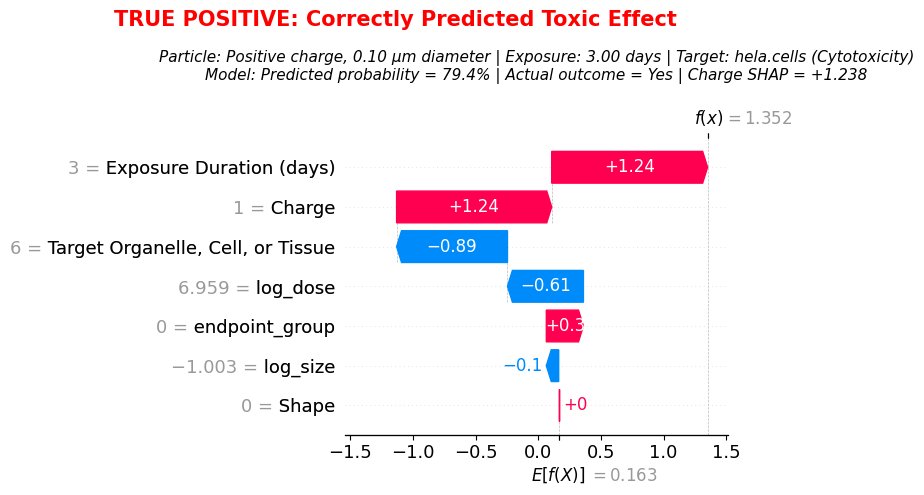


📊 INTERPRETATION:
----------------------------------------------------------------------------------------------------
  ✓ Positive charge contributed +1.238 to toxicity prediction
  ✓ This particle was correctly flagged as toxic
  ✓ ALARA implication: Avoiding positive charge would reduce risk

EXAMPLE 2: Index 32

Sample Characteristics:
----------------------------------------------------------------------------------------------------
  log_dose                                : 8.65 (10^8.7 = 4.49e+08 particles)                  SHAP: +1.1829
  log_size                                : -1.33 (10^-1.3 = 0.05 μm)                           SHAP: -0.3692
  Exposure Duration (days)                : 1.00 days                                           SHAP: -0.0631
  Shape                                   : Sphere                                              SHAP: +0.0000
  Charge                                  : negative                                            SHAP: -0.4120
  Targ

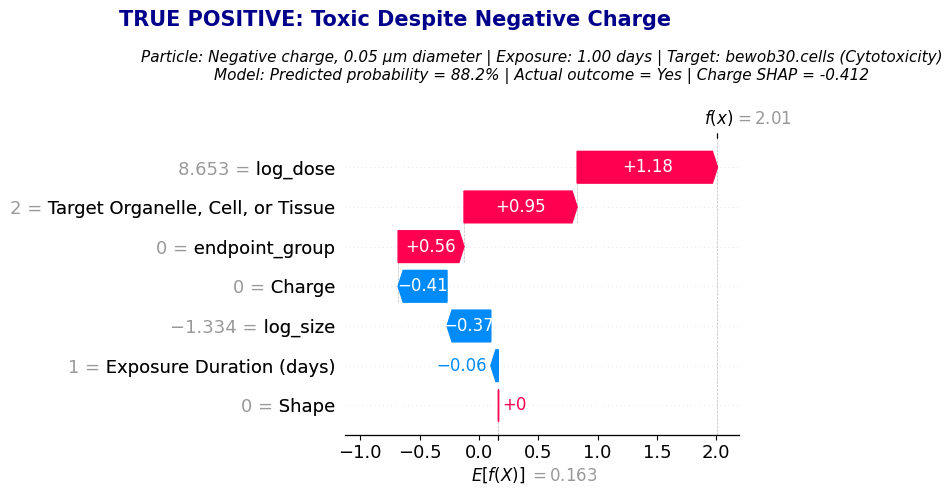


📊 INTERPRETATION:
----------------------------------------------------------------------------------------------------
  ! Negative charge contributed -0.412 to prediction (protective)
  ! BUT particle was still toxic due to other factors:
    Top risk factors:
      1. log_dose: SHAP = +1.183
      2. Target Organelle, Cell, or Tissue: SHAP = +0.953
      3. endpoint_group: SHAP = +0.555
  ✓ Even negative charge can't always prevent toxicity at high dose/vulnerable tissues

EXAMPLE 3: Index 0

Sample Characteristics:
----------------------------------------------------------------------------------------------------
  log_dose                                : 7.12 (10^7.1 = 1.31e+07 particles)                  SHAP: +0.8567
  log_size                                : -0.62 (10^-0.6 = 0.24 μm)                           SHAP: -0.0865
  Exposure Duration (days)                : 0.67 days                                           SHAP: -0.3144
  Shape                                   : 

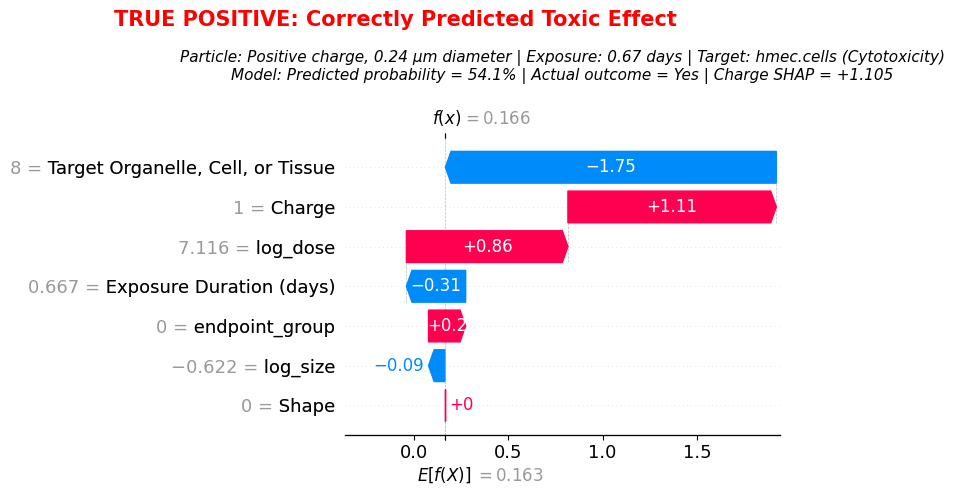


📊 INTERPRETATION:
----------------------------------------------------------------------------------------------------
  ✓ Positive charge contributed +1.105 to toxicity prediction
  ✓ This particle was correctly flagged as toxic
  ✓ ALARA implication: Avoiding positive charge would reduce risk


📊 COMPARISON ACROSS EXAMPLES

🔬 Key Findings:
----------------------------------------------------------------------------------------------------

  Positive Charge Examples (n=2):
    Mean charge SHAP: +1.172
    → Charge consistently INCREASES toxicity risk

  Negative Charge Examples (n=1):
    Mean charge SHAP: -0.412
    → Charge DECREASES risk, but other factors dominate

  ✅ CHARGE EFFECT IS CONSISTENT AND DIRECTIONAL
     Even when outcome is the same (toxic), charge pushes prediction in expected direction

✓ Waterfall plots with decoded features complete!


In [3]:
print("\n" + "="*100)
print("SHAP WATERFALL PLOTS: True Positives with Decoded Features")
print("="*100)

import matplotlib.pyplot as plt

# ============================================================================
# DECODE FEATURE VALUES FOR DISPLAY
# ============================================================================
print("\n🔧 Creating decoded feature display...")

def decode_feature_display(sample_idx, X_test, feature_names, label_encoders):
    """Create human-readable feature values for display"""
    
    feature_display = {}
    
    for i, feat_name in enumerate(feature_names):
        value = X_test[sample_idx, i]
        
        # Categorical features - decode
        if feat_name in label_encoders:
            decoded = label_encoders[feat_name].inverse_transform([int(value)])[0]
            feature_display[feat_name] = decoded
        
        # Continuous features - show actual value
        else:
            if feat_name == 'log_dose':
                # Show both log and original
                original_dose = 10**value
                feature_display[feat_name] = f"{value:.2f} (10^{value:.1f} = {original_dose:.2e} particles)"
            elif feat_name == 'log_size':
                # Show both log and original
                original_size = 10**value
                feature_display[feat_name] = f"{value:.2f} (10^{value:.1f} = {original_size:.2f} μm)"
            elif feat_name == 'Exposure Duration (days)':
                feature_display[feat_name] = f"{value:.2f} days"
            else:
                feature_display[feat_name] = f"{value:.2f}"
    
    return feature_display

# ============================================================================
# FIND TRUE POSITIVE EXAMPLES
# ============================================================================
print("\n🔍 Finding True Positive Examples (Actual=Yes, Predicted=Yes)")
print("="*100)

# True positives
tp_mask = (y_test == 1) & (y_test_pred == 1)
tp_indices = np.where(tp_mask)[0]

print(f"True Positives: {tp_mask.sum()} samples")

if tp_mask.sum() > 0:
    # Decode charge for filtering
    charge_idx = feature_names.index('Charge')
    charge_labels_tp = label_encoders['Charge'].inverse_transform(X_test[tp_indices, charge_idx].astype(int))
    
    # Find examples
    tp_pos_indices = tp_indices[charge_labels_tp == 'positive']
    tp_neg_indices = tp_indices[charge_labels_tp == 'negative']
    
    print(f"\n  True Positives with POSITIVE charge: {len(tp_pos_indices)}")
    print(f"  True Positives with NEGATIVE charge: {len(tp_neg_indices)}")
    
    # Select representative examples
    examples = []
    
    # Example 1: Positive charge true positive with highest SHAP
    if len(tp_pos_indices) > 0:
        pos_shaps = shap_values[tp_pos_indices, charge_idx]
        best_pos_idx = tp_pos_indices[np.argmax(pos_shaps)]
        examples.append(('positive', best_pos_idx))
        print(f"\n  Example 1: Positive charge (Index {best_pos_idx})")
    
    # Example 2: Negative charge true positive (toxic despite negative charge)
    if len(tp_neg_indices) > 0:
        # Find one with highest prediction probability
        neg_probas = y_test_proba[tp_neg_indices]
        best_neg_idx = tp_neg_indices[np.argmax(neg_probas)]
        examples.append(('negative', best_neg_idx))
        print(f"  Example 2: Negative charge (Index {best_neg_idx})")
    
    # Example 3: Another positive charge with different tissue if available
    if len(tp_pos_indices) > 1:
        # Get tissue for first example
        tissue_idx = feature_names.index('Target Organelle, Cell, or Tissue')
        first_tissue = X_test[examples[0][1], tissue_idx] if examples else None
        
        # Find different tissue
        for idx in tp_pos_indices:
            if idx != examples[0][1] and X_test[idx, tissue_idx] != first_tissue:
                examples.append(('positive_alt', idx))
                print(f"  Example 3: Positive charge, different tissue (Index {idx})")
                break
    
    # ========================================================================
    # CREATE WATERFALL PLOTS
    # ========================================================================
    
    for example_num, (charge_type, sample_idx) in enumerate(examples, 1):
        
        print(f"\n{'='*100}")
        print(f"EXAMPLE {example_num}: Index {sample_idx}")
        print(f"{'='*100}")
        
        # Decode all features
        feature_display = decode_feature_display(sample_idx, X_test, feature_names, label_encoders)
        
        # Get prediction info
        pred_proba = y_test_proba[sample_idx]
        actual = le_target.inverse_transform([y_test[sample_idx]])[0]
        predicted = le_target.inverse_transform([y_test_pred[sample_idx]])[0]
        charge_shap = shap_values[sample_idx, charge_idx]
        
        # Print summary
        print(f"\nSample Characteristics:")
        print("-"*100)
        for feat, val in feature_display.items():
            shap_idx = feature_names.index(feat)
            shap_val = shap_values[sample_idx, shap_idx]
            print(f"  {feat:40s}: {val:50s}  SHAP: {shap_val:+.4f}")
        
        print(f"\nPrediction:")
        print(f"  Actual Outcome: {actual}")
        print(f"  Predicted: {predicted}")
        print(f"  Probability: {pred_proba:.3f}")
        print(f"  Base value: {explainer.expected_value:.3f}")
        
        # Create detailed title
        charge_val = feature_display['Charge']
        tissue_val = feature_display['Target Organelle, Cell, or Tissue']
        endpoint_val = feature_display['endpoint_group']
        
        # Extract just the size value
        size_display = feature_display['log_size'].split('(')[1].split('=')[1].split(')')[0].strip()
        
        # Main title
        if charge_val == 'positive':
            title_color = 'red'
            main_title = f"TRUE POSITIVE: Correctly Predicted Toxic Effect"
        else:
            title_color = 'darkblue'
            main_title = f"TRUE POSITIVE: Toxic Despite Negative Charge"
        
        # Subtitle with details
        subtitle = (f"Particle: {charge_val.title()} charge, {size_display} diameter | "
                   f"Exposure: {feature_display['Exposure Duration (days)']} | "
                   f"Target: {tissue_val} ({endpoint_val})\n"
                   f"Model: Predicted probability = {pred_proba:.1%} | "
                   f"Actual outcome = {actual} | "
                   f"Charge SHAP = {charge_shap:+.3f}")
        
        # Create waterfall plot
        plt.figure(figsize=(14, 10))
        shap.plots.waterfall(shap_explanation[sample_idx], max_display=10, show=False)
        
        # Add custom title
        plt.suptitle(main_title, 
                    fontsize=15, fontweight='bold', color=title_color, y=0.98)
        plt.title(subtitle, 
                 fontsize=11, style='italic', pad=20, color='black')
        
        plt.tight_layout()
        plt.show()
        
        # Add interpretation
        print(f"\n📊 INTERPRETATION:")
        print("-"*100)
        
        if charge_val == 'positive':
            print(f"  ✓ Positive charge contributed +{charge_shap:.3f} to toxicity prediction")
            print(f"  ✓ This particle was correctly flagged as toxic")
            print(f"  ✓ ALARA implication: Avoiding positive charge would reduce risk")
        else:
            print(f"  ! Negative charge contributed {charge_shap:.3f} to prediction (protective)")
            print(f"  ! BUT particle was still toxic due to other factors:")
            
            # Find top contributing factors
            abs_shaps = np.abs(shap_values[sample_idx, :])
            top_features_idx = np.argsort(abs_shaps)[::-1][:3]
            
            print(f"    Top risk factors:")
            for i, feat_idx in enumerate(top_features_idx, 1):
                feat_name = feature_names[feat_idx]
                feat_shap = shap_values[sample_idx, feat_idx]
                if feat_shap > 0:  # Only show positive contributors
                    print(f"      {i}. {feat_name}: SHAP = +{feat_shap:.3f}")
            
            print(f"  ✓ Even negative charge can't always prevent toxicity at high dose/vulnerable tissues")

else:
    print("\n⚠️  No true positive samples found in test set")

# ============================================================================
# SUMMARY COMPARISON
# ============================================================================
if len(examples) >= 2:
    print("\n\n" + "="*100)
    print("📊 COMPARISON ACROSS EXAMPLES")
    print("="*100)
    
    print("\n🔬 Key Findings:")
    print("-"*100)
    
    pos_examples = [ex for ex in examples if ex[0].startswith('positive')]
    neg_examples = [ex for ex in examples if ex[0] == 'negative']
    
    if pos_examples:
        pos_shaps = [shap_values[ex[1], charge_idx] for ex in pos_examples]
        print(f"\n  Positive Charge Examples (n={len(pos_examples)}):")
        print(f"    Mean charge SHAP: +{np.mean(pos_shaps):.3f}")
        print(f"    → Charge consistently INCREASES toxicity risk")
    
    if neg_examples:
        neg_shaps = [shap_values[ex[1], charge_idx] for ex in neg_examples]
        print(f"\n  Negative Charge Examples (n={len(neg_examples)}):")
        print(f"    Mean charge SHAP: {np.mean(neg_shaps):.3f}")
        print(f"    → Charge DECREASES risk, but other factors dominate")
    
    print(f"\n  ✅ CHARGE EFFECT IS CONSISTENT AND DIRECTIONAL")
    print(f"     Even when outcome is the same (toxic), charge pushes prediction in expected direction")

print("\n" + "="*100)
print("✓ Waterfall plots with decoded features complete!")
print("="*100)